# Exercise 1: Best Execution Environment

Este notebook parte de `workshop/execution_lab.ipynb` y muestra el uso del entorno modularizado `BestExecutionEnv`. El objetivo es entrenar un agente DDQN con datos reales y evaluar su ejecución en un episodio completo, sin duplicar la implementación disponible en `src`.

## Datos

Los datos contienen la primera posición del libro de órdenes (`ask1` y `bid1`) y el volumen acumulado (`cumvol`), agrupados en intervalos de cinco segundos. Para este ejercicio se utiliza la partición de entrenamiento de Repsol.

In [19]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from src.agents.dqn import DDQNAgent
from src.environment.best_execution import BestExecutionEnv
from src.environment.config import EnvironmentConfig
from src.report.report import plot_results
from src.rewards import VwapRewardStrategy

In [20]:
repo_root = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "setup.py").exists() and (path / "src").is_dir()
)

with (repo_root / "data" / "rep_data.pkl").open("rb") as file:
    data_splits = pickle.load(file)

data = data_splits["train"]
data_splits.keys()

dict_keys(['train', 'val', 'test'])

## Configuración del entorno

La semilla forma parte de `EnvironmentConfig`. Dos entornos creados con la misma configuración y los mismos datos producirán la misma secuencia de episodios y acciones aleatorias.

In [21]:
config = EnvironmentConfig(look_back=60, seed=42)
reward_strategy = VwapRewardStrategy()
env = BestExecutionEnv(
    data=data,
    config=config,
    reward_strategy=reward_strategy,
)

observation = env.reset()
pd.Series(
    {
        "episode_bins": env.episode_bins,
        "care_volume": env.vol_care,
        "num_features": env.n_features,
        "observation_shape": observation.shape,
    }
)

episode_bins          417
care_volume            40
num_features            2
observation_shape    (2,)
dtype: object

## Entrenamiento del agente DDQN

El entrenamiento incluye el calentamiento del replay buffer, aprendizaje periódico y sincronización de la red objetivo. El número de episodios se mantiene moderado para que el ejercicio pueda ejecutarse de principio a fin; puede aumentarse para realizar un entrenamiento más exhaustivo.

In [22]:
seed = 42
tf.keras.utils.set_random_seed(seed)

initial_epsilon = 1.0
min_epsilon = 0.05
gamma = 0.99
alpha = 0.001
batch_size = 32
buffer_size = 2_000
hidden_neurons = 32
num_episodes = 10
warmup_steps = 256
learn_every = 16
target_update_every = 128
epsilon_decay = (initial_epsilon - min_epsilon) / num_episodes

agent = DDQNAgent(
    env=env,
    gamma=gamma,
    epsilon=initial_epsilon,
    alpha=alpha,
    batch_size=batch_size,
    buffer_size=buffer_size,
    hidden_neurons=hidden_neurons,
    trainable=True,
)

### Motivación de los hiperparámetros

Estos valores priorizan una demostración reproducible y ejecutable en un tiempo razonable. No representan una calibración exhaustiva ni permiten afirmar que el agente haya convergido.

| Hiperparámetro | Valor | Motivación |
|---|---:|---|
| Semilla | `42` | Permite repetir la inicialización del modelo y la secuencia de episodios. |
| `gamma` | `0.99` | Da peso a recompensas futuras y a la penalización terminal en episodios largos. |
| `alpha` | `0.001` | Es un learning rate conservador para mantener estables las actualizaciones con Adam. |
| `epsilon` | `1.0` → `0.05` | Comienza con exploración completa y conserva una pequeña probabilidad exploratoria al final. |
| `batch_size` | `32` | Ofrece diversidad en cada actualización sin encarecer demasiado la ejecución del notebook. |
| `buffer_size` | `2_000` | Conserva transiciones de varios episodios recientes con un consumo de memoria reducido. |
| Neuronas ocultas | `32` | Dos capas pequeñas son suficientes como punto de partida para un estado de baja dimensión. |
| Calentamiento | `256` pasos | Aporta ocho batches de experiencias antes del primer aprendizaje. |
| Frecuencia de aprendizaje | Cada `16` pasos | Reduce el coste y la correlación entre actualizaciones consecutivas. |
| Actualización de la red objetivo | Cada `128` pasos | Mantiene el objetivo fijo durante ocho actualizaciones de aprendizaje. |
| Episodios | `10` | Permite verificar el flujo completo con rapidez; debe aumentarse para estudiar convergencia. |

### Calentamiento del replay buffer

Antes de actualizar la red neuronal se recopilan transiciones con la política aleatoria del entorno.

In [23]:
state = env.reset()

for _ in range(warmup_steps):
    action = env.action_sample()
    next_state, reward, done, _ = env.step(action)
    agent.experience(state, action, reward, next_state, done)
    state = env.reset() if done else next_state

len(agent.buffer)

256

In [24]:
training_records = []
global_step = 0
agent.set_trainable(True)

for episode in range(1, num_episodes + 1):
    state = env.reset()
    done = False
    cumulative_reward = 0.0
    episode_losses = []

    while not done:
        action = agent.act(state)
        next_state, reward, done, _ = env.step(action)
        agent.experience(state, action, reward, next_state, done)

        global_step += 1
        cumulative_reward += reward

        if global_step % learn_every == 0:
            episode_losses.append(float(agent.learn()))
        if global_step % target_update_every == 0:
            agent.update_target()

        state = next_state

    agent.epsilon = max(agent.epsilon - epsilon_decay, min_epsilon)
    training_records.append(
        {
            "episode": episode,
            "steps": env.state_pos,
            "cumulative_reward": cumulative_reward,
            "mean_loss": np.mean(episode_losses),
            "epsilon": agent.epsilon,
        }
    )

training_history = pd.DataFrame(training_records)
training_history

,episode,steps,cumulative_reward,mean_loss,epsilon
0,1,414,-0.018362,3.386433e-05,0.905
1,2,316,-0.012883,6.364898e-06,0.810
2,3,472,-0.010723,5.213867e-06,0.715
3,4,496,-0.030179,9.191007e-07,0.620
4,5,320,0.027270,2.273610e-06,0.525
5,6,549,0.034451,1.186689e-06,0.430
6,7,534,-0.020855,7.032837e-07,0.335
7,8,588,-0.022340,6.623904e-07,0.240
8,9,191,-0.084870,3.414052e-06,0.145
9,10,228,-0.010645,3.680663e-06,0.050


array([<Axes: xlabel='episode'>, <Axes: xlabel='episode'>], dtype=object)

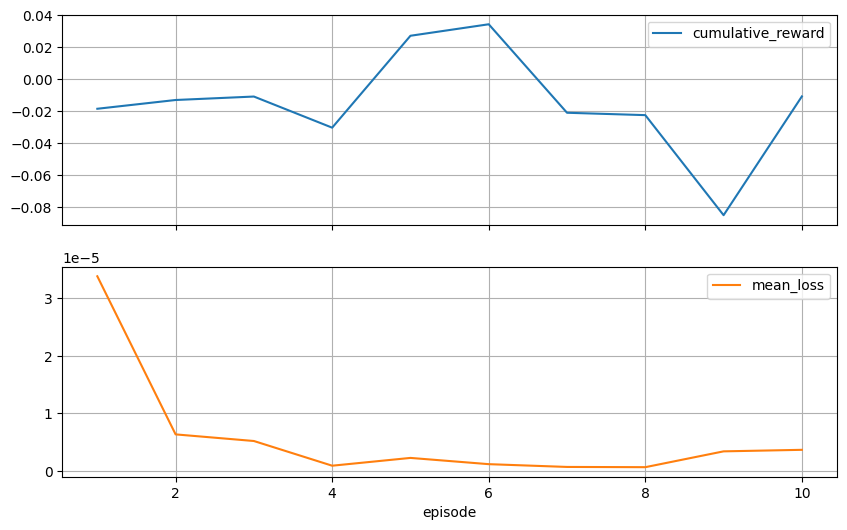

In [25]:
training_history.set_index("episode")[
    ["cumulative_reward", "mean_loss"]
].plot(subplots=True, figsize=(10, 6), grid=True)

## Evaluación: ejecución de un episodio completo

Se desactiva la exploración y se evalúa el agente entrenado sobre la partición `test`. El episodio finaliza cuando se completa la orden CARE o se agota el tiempo disponible.

In [26]:
evaluation_env = BestExecutionEnv(
    data=data_splits["test"],
    config=EnvironmentConfig(look_back=60, seed=2026),
    reward_strategy=VwapRewardStrategy(),
)
agent.env = evaluation_env
agent.set_trainable(False)

state = evaluation_env.reset()
done = False
cumulative_reward = 0.0

while not done:
    action = agent.act(state)
    state, reward, done, info = evaluation_env.step(action)
    cumulative_reward += reward

stop_reason = (
    "CARE order completed"
    if evaluation_env.exec_vol >= evaluation_env.vol_care
    else "time exhausted"
)
evaluation_summary = pd.Series(
    {
        "stop_reason": stop_reason,
        "steps": evaluation_env.state_pos,
        "episode_bins": evaluation_env.episode_bins,
        "executed_volume": evaluation_env.exec_vol,
        "care_volume": evaluation_env.vol_care,
        "cumulative_reward": cumulative_reward,
        "algorithm_vwap": evaluation_env.algo_vwap_hist[-1],
        "market_vwap": evaluation_env.market_vwap_hist[-1],
        "episode_vwap": evaluation_env.episode_vwap,
    }
)
evaluation_summary

stop_reason          CARE order completed
steps                                  61
episode_bins                          571
executed_volume                        61
care_volume                            61
cumulative_reward               -0.003136
algorithm_vwap                  15.108525
market_vwap                     15.106617
episode_vwap                    15.107748
dtype: object

In [27]:
evaluation_history = pd.DataFrame(
    {
        "action": evaluation_env.actions_hist,
        "price": evaluation_env.price_hist,
        "volume": evaluation_env.vol_hist,
        "algorithm_vwap": evaluation_env.algo_vwap_hist,
        "market_vwap": evaluation_env.market_vwap_hist,
        "reward": evaluation_env.reward_hist,
    }
)

assert done
assert state is None
assert len(evaluation_history) == evaluation_env.state_pos
assert evaluation_env.state_pos <= evaluation_env.episode_bins
assert evaluation_env.exec_vol <= evaluation_env.vol_care

evaluation_history.head()

,action,price,volume,algorithm_vwap,market_vwap,reward
0,1,15.110,1,15.110000,15.107500,-0.000149
1,1,15.110,1,15.110000,15.107500,-0.000149
2,1,15.105,1,15.108333,15.107500,0.000182
3,1,15.105,1,15.107500,15.107500,0.000182
4,1,15.105,1,15.107000,15.106917,0.000182


## Resultados de la evaluación

La visualización compara la ejecución del agente entrenado con la evolución del mercado durante el episodio de evaluación.

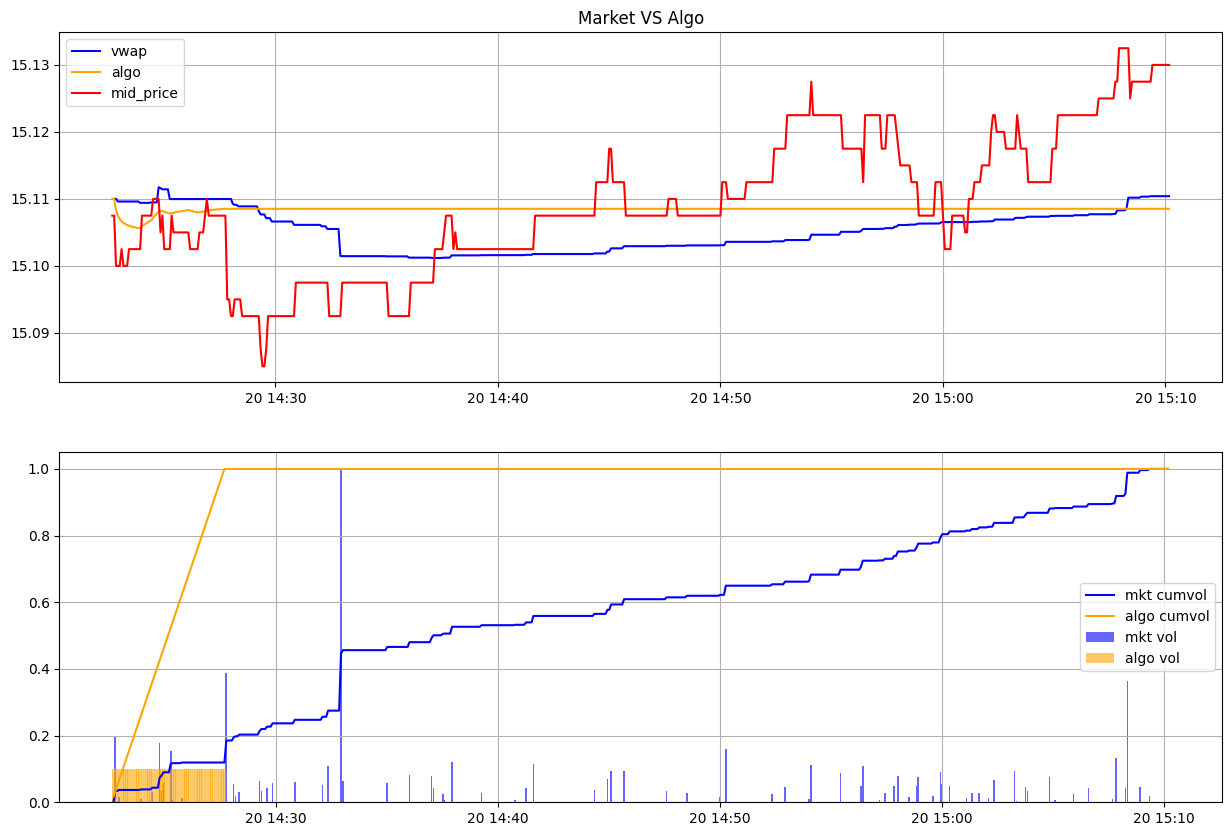

In [28]:
plot_results(evaluation_env)